# Step 3 - Features and frozen scaler

Compute the five centralities of the cleaned graph, fit the Min-Max scaler on it (once), and save both.
Logic is in `src/features.py` and `src/scaling.py`.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Final-Project'):
    !git clone https://github.com/ShaharBar99/Final-Project.git
    %cd Final-Project
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

## 1. Load the cleaned graph and compute the features

In [2]:
import time
import pandas as pd
from src import config, data, features, scaling

g, nodes = data.load_clean_graph()
start = time.time()
raw = features.compute_features(g)
print(f'{len(raw)} papers, computed in {time.time() - start:.1f} s')
raw.describe().T

19717 papers, computed in 0.9 s


,count,mean,std,min,25%,50%,75%,max
degree,19717.0,2.280391e-04,0.000377,0.000051,0.000051,0.000101,0.000203,0.008673
betweenness,19717.0,2.756776e-07,0.000003,0.000000,0.000000,0.000000,0.000000,0.000173
closeness,19717.0,4.187194e-04,0.001059,0.000000,0.000051,0.000091,0.000203,0.013561
pagerank,19717.0,5.071765e-05,0.000017,0.000042,0.000044,0.000046,0.000051,0.000772
kcore,19717.0,2.394533e+00,1.930864,1.000000,1.000000,2.000000,3.000000,10.000000


## 2. Look before trusting

Many papers have zero betweenness: citations only point back in time, so most papers are either never cited or cite nothing inside the dataset and cannot sit *between* two others.

In [3]:
print('papers with betweenness > 0:', (raw['betweenness'] > 0).sum())
print('papers with closeness = 0   :', (raw['closeness'] == 0).sum())
print('k-core values:', raw['kcore'].value_counts().sort_index().to_dict())
raw.corr(method='spearman').round(2)

papers with betweenness > 0: 1807
papers with closeness = 0   : 2047
k-core values: {1: 9313, 2: 3936, 3: 2267, 4: 1571, 5: 1061, 6: 632, 7: 247, 8: 230, 9: 323, 10: 137}


,degree,betweenness,closeness,pagerank,kcore
degree,1.00,0.46,0.31,0.29,0.97
betweenness,0.46,1.00,0.16,0.19,0.42
closeness,0.31,0.16,1.00,0.73,0.41
pagerank,0.29,0.19,0.73,1.00,0.37
kcore,0.97,0.42,0.41,0.37,1.00


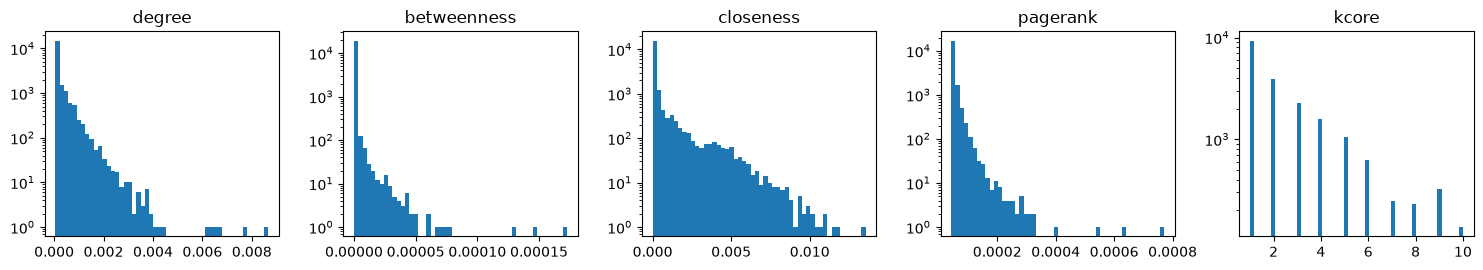

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 5, figsize=(15, 2.8))
for ax, col in zip(axes, raw.columns):
    ax.hist(raw[col], bins=50, log=True)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 3. Fit the scaler on this graph (frozen from now on) and save everything

In [5]:
import joblib
scaler = scaling.fit_scaler(raw)
scaled = scaling.apply_scaler(scaler, raw)
print('scaled range:', scaled.min().min(), 'to', scaled.max().max())

raw.to_csv(config.PROCESSED_DIR / 'features_raw.csv', index_label='paper_id')
scaled.to_csv(config.PROCESSED_DIR / 'features_scaled.csv', index_label='paper_id')
joblib.dump(scaler, config.PROCESSED_DIR / 'scaler.joblib')

scaled range: 0.0 to 1.0000000000000002


['C:\\Users\\shahar_b\\Documents\\Claude\\FinalProject\\data\\processed\\scaler.joblib']